# EEG Analysis Pipeline — Mathematics Group

This notebook is configured for the Mathematics group (`Mc01`–`Mc22`).

**Recording structure per subject:**
- `ses-1`, run-1: PRE Baseline
- `ses-1`, run-2: PRE Activity 1
- `ses-1`, run-3: PRE Activity 2
- `ses-2`, run-1: POST Baseline
- `ses-2`, run-2: POST Activity 1
- `ses-2`, run-3: POST Activity 2

**Workflow:** configure cohort → validate and extract complete subjects → inspect the cohort summary → load one valid subject for plots → preprocess six recordings → inspect event markers → compare matching PRE/POST conditions → calculate band power → update the Mathematics master CSV.

The cohort extraction section can be run independently to process all subjects incrementally. Subjects are included in the master CSV only when all six recordings pass the configured validation checks. Missing event TSV files do not invalidate signal-level band-power extraction; event-specific analysis is skipped unless valid event times are explicitly configured.

## 1. Subject selection and project configuration

In [61]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import mne
import matplotlib.pyplot as plt
from scipy.signal import welch

# ---------- MATHEMATICS GROUP SETTINGS ----------
SUBJECT_ID = "Mc01"  # Subject used for the single-subject plots below
SUBJECT_ID = SUBJECT_ID.replace("sub-", "").strip()

# The Math-group filenames supplied so far use this task label.
# If the actual filenames use another task label, change this to match exactly.
TASK_NAME = "SmartickDataset"

# Find the project root from the current folder or one of its parents.
_here = Path.cwd().resolve()
_candidates = [_here, *_here.parents]
ROOT = next(
    (
        candidate for candidate in _candidates
        if any(candidate.glob("sub-Mc*"))
    ),
    None
)
if ROOT is None:
    raise FileNotFoundError(
        "Could not locate the Mathematics dataset root. The current directory "
        "or one of its parents must contain folders such as sub-Mc01."
    )

BIDS_SUBJECT = f"sub-{SUBJECT_ID}"
SUBJECT_DIR = ROOT / BIDS_SUBJECT
RESULTS_DIR = ROOT / "Results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Cohort and single-subject results use the same Mathematics-specific master CSV.
CSV_FILE = RESULTS_DIR / "eeg_analysis_results_math_control.csv"
COHORT_CSV_FILE = CSV_FILE
COHORT_AUDIT_FILE = RESULTS_DIR / "subject_processing_summary_math_control.csv"

# PRE = ses-1; POST = ses-2. Each session has baseline + two activity runs.
RECORDINGS = {
    "PRE_Baseline":  ("ses-1", 1),
    "PRE_Activity1": ("ses-1", 2),
    "PRE_Activity2": ("ses-1", 3),
    "POST_Baseline":  ("ses-2", 1),
    "POST_Activity1": ("ses-2", 2),
    "POST_Activity2": ("ses-2", 3),
}

# Event times are deliberately unset: do not reuse timestamps from the RC group.
# After checking the Math event TSVs and event-code documentation, enter seconds
# for the corresponding activity recording, e.g. "PRE_Activity1": 123.45.
EVENT_TIMES = {
    "PRE_Activity1": None,
    "PRE_Activity2": None,
    "POST_Activity1": None,
    "POST_Activity2": None,
}
EVENT_WINDOW_BEFORE = 2.0
EVENT_WINDOW_AFTER = 3.0

# Use the acquisition metadata to verify whether another notch is appropriate.
# This remains disabled by default.
APPLY_ADDITIONAL_NOTCH = False
POWER_LINE_FREQUENCY = 60

# Shared plotting settings.
SELECTED_CHANNELS = ["T8", "O1"]
SELECTED_SIGNAL_RECORDING = "PRE_Activity1"
PLOT_WINDOW_SECONDS = (0.0, 5.0)

print("Mathematics group subject:", BIDS_SUBJECT)
print("Project root:", ROOT)
print("Task label used in filenames:", TASK_NAME)
print("Mathematics master CSV:", CSV_FILE)

Mathematics group subject: sub-Mc01
Project root: /Users/ananyosen/Documents/Term Project
Task label used in filenames: SmartickDataset
Mathematics master CSV: /Users/ananyosen/Documents/Term Project/Results/eeg_analysis_results_math_control.csv


## Mathematics cohort extraction — process only complete, consistent subjects

**Use this section for the master CSV.** Run the configuration cell, then the cohort extraction cell and the cohort summary cell.

- `SUBJECTS_TO_PROCESS` defaults to `Mc01`–`Mc22`; it can be reduced to one subject when retrying.
- A subject is accepted only when all six `.set`, `.json`, and `channels.tsv` files exist, all six SET files load, the signals contain finite data, and channel names/order and sampling frequency agree across all six recordings.
- Activity `events.tsv` files are recorded in the audit but are **not required** for whole-recording band-power extraction. They are required for event-specific analyses.
- Invalid subjects are skipped without stopping the remaining cohort. Their reasons are saved in the cumulative quality-control report.
- Existing master-CSV rows are replaced only for subjects successfully reprocessed. A skipped subject's previous results, if any, are left untouched.


In [62]:
# ---------- MATHEMATICS COHORT SETTINGS ----------
# Process the full expected cohort, or replace with a smaller retry list.
SUBJECTS_TO_PROCESS = [f"Mc{i:02d}" for i in range(1, 23)]
# Example for a single retry:
# SUBJECTS_TO_PROCESS = ["Mc15"]

REQUIRE_JSON_AND_CHANNELS_TSV = True
EXPECTED_CHANNEL_COUNT = 32

COHORT_RECORDINGS = RECORDINGS.copy()

COHORT_BANDS = {
    "delta": (0.5, 4.0),
    "theta": (4.0, 8.0),
    "alpha": (8.0, 13.0),
    "beta": (13.0, 30.0),
    "gamma": (30.0, 50.0),
}
COHORT_TOTAL_RANGE = (0.5, 50.0)

COHORT_CSV_COLUMNS = [
    "subject_id", "session", "run", "condition",
    "sampling_frequency", "duration", "channel_count", "sample_count",
    "channel", "band", "frequency_min", "frequency_max",
    "absolute_power", "relative_power",
    "event_id", "event_onset", "event_duration", "event_code"
]

def _cohort_integrate_psd(freqs, psd, low, high):
    mask = (freqs >= low) & (freqs <= high)
    if mask.sum() < 2:
        return np.nan
    integrate = getattr(np, "trapezoid", None)
    if integrate is None:
        integrate = np.trapz
    return float(integrate(psd[mask], freqs[mask]))

def _math_condition(recording_name):
    if "Baseline" in recording_name:
        return "Baseline"
    if "Activity1" in recording_name:
        return "Activity1"
    if "Activity2" in recording_name:
        return "Activity2"
    raise ValueError(f"Unknown recording label: {recording_name}")

def _cohort_validate_and_load(subject_id):
    subject_dir = ROOT / f"sub-{subject_id}"
    if not subject_dir.is_dir():
        raise FileNotFoundError(f"Subject folder not found: {subject_dir}")

    loaded = {}
    paths = {}
    missing = []

    for rec_name, (session, run) in COHORT_RECORDINGS.items():
        eeg_dir = subject_dir / session / "eeg"
        prefix = (
            f"sub-{subject_id}_{session}_task-{TASK_NAME}_run-{run}"
        )
        files = {
            "SET": eeg_dir / f"{prefix}_eeg.set",
            "JSON": eeg_dir / f"{prefix}_eeg.json",
            "channels.tsv": eeg_dir / f"{prefix}_channels.tsv",
            "events.tsv": eeg_dir / f"{prefix}_events.tsv",
        }

        for kind, path in files.items():
            required = (
                kind == "SET"
                or (REQUIRE_JSON_AND_CHANNELS_TSV and kind in {"JSON", "channels.tsv"})
            )
            if required and not path.is_file():
                missing.append(f"{rec_name}: missing {kind} ({path.name})")

        if files["SET"].is_file():
            paths[rec_name] = files

    if missing:
        raise ValueError("; ".join(missing))

    # Load all six recordings. Any failure invalidates the subject as a whole.
    for rec_name, files in paths.items():
        try:
            raw = mne.io.read_raw_eeglab(
                files["SET"], preload=True, verbose="ERROR"
            )
        except Exception as exc:
            raise RuntimeError(
                f"{rec_name}: SET could not be loaded "
                f"({type(exc).__name__}: {exc})"
            ) from exc

        if raw.n_times < 2 or len(raw.ch_names) == 0:
            raise ValueError(f"{rec_name}: empty signal or no channels")

        if not np.isfinite(raw.get_data()).all():
            raise ValueError(
                f"{rec_name}: signal contains NaN or infinite samples"
            )

        try:
            with open(files["JSON"], "r", encoding="utf-8") as f:
                metadata = json.load(f)
        except Exception as exc:
            raise ValueError(
                f"{rec_name}: JSON metadata could not be read "
                f"({type(exc).__name__}: {exc})"
            ) from exc

        try:
            channel_table = pd.read_csv(files["channels.tsv"], sep="\t")
        except Exception as exc:
            raise ValueError(
                f"{rec_name}: channels.tsv could not be read "
                f"({type(exc).__name__}: {exc})"
            ) from exc

        if "name" not in channel_table.columns:
            raise ValueError(f"{rec_name}: channels.tsv has no 'name' column")

        tsv_names = channel_table["name"].astype(str).tolist()
        if tsv_names != raw.ch_names:
            raise ValueError(
                f"{rec_name}: channels.tsv names/order do not match SET channel names"
            )

        loaded[rec_name] = {
            "raw": raw,
            "metadata": metadata,
            "files": files,
            "events_file": files["events.tsv"],
        }

    if len(loaded) != len(COHORT_RECORDINGS):
        raise ValueError(
            f"Expected {len(COHORT_RECORDINGS)} recordings; loaded {len(loaded)}"
        )

    # Cross-recording consistency checks.
    first_name = list(loaded)[0]
    reference_raw = loaded[first_name]["raw"]
    reference_channels = reference_raw.ch_names
    reference_sfreq = float(reference_raw.info["sfreq"])

    if len(reference_channels) != EXPECTED_CHANNEL_COUNT:
        raise ValueError(
            f"{first_name}: expected {EXPECTED_CHANNEL_COUNT} channels, "
            f"found {len(reference_channels)}"
        )

    for rec_name, item in loaded.items():
        raw = item["raw"]
        if raw.ch_names != reference_channels:
            raise ValueError(
                f"{rec_name}: channel names or order differ from {first_name}"
            )
        if not np.isclose(float(raw.info["sfreq"]), reference_sfreq):
            raise ValueError(
                f"{rec_name}: sampling frequency {raw.info['sfreq']} Hz "
                f"differs from {reference_sfreq} Hz"
            )
        if raw.info["sfreq"] / 2 < max(
            high for _, high in COHORT_BANDS.values()
        ):
            raise ValueError(
                f"{rec_name}: Nyquist frequency is below 50 Hz"
            )

    return loaded

def _cohort_extract_subject(subject_id):
    loaded = _cohort_validate_and_load(subject_id)
    rows = []

    for rec_name, item in loaded.items():
        raw = item["raw"].copy()
        raw.filter(
            l_freq=0.5, h_freq=50.0,
            fir_design="firwin", verbose="ERROR"
        )

        session, run = COHORT_RECORDINGS[rec_name]
        condition = _math_condition(rec_name)
        sfreq = float(raw.info["sfreq"])
        nperseg = min(2048, raw.n_times)

        if nperseg < 16:
            raise ValueError(
                f"{rec_name}: recording is too short for Welch PSD"
            )

        for channel in raw.ch_names:
            signal_uv = raw.get_data(picks=[channel])[0] * 1e6
            freqs, psd = welch(
                signal_uv,
                fs=sfreq,
                nperseg=nperseg,
                noverlap=nperseg // 2,
                scaling="density"
            )
            total_power = _cohort_integrate_psd(
                freqs, psd, *COHORT_TOTAL_RANGE
            )

            for band, (low, high) in COHORT_BANDS.items():
                absolute_power = _cohort_integrate_psd(
                    freqs, psd, low, high
                )
                relative_power = (
                    absolute_power / total_power * 100
                    if np.isfinite(total_power) and total_power > 0
                    else np.nan
                )
                if (
                    not np.isfinite(absolute_power)
                    or not np.isfinite(relative_power)
                ):
                    raise ValueError(
                        f"{rec_name}, {channel}, {band}: "
                        "non-finite band-power result"
                    )

                rows.append({
                    "subject_id": subject_id,
                    "session": session,
                    "run": run,
                    "condition": condition,
                    "sampling_frequency": sfreq,
                    "duration": float(raw.times[-1]),
                    "channel_count": len(raw.ch_names),
                    "sample_count": raw.n_times,
                    "channel": channel,
                    "band": band,
                    "frequency_min": low,
                    "frequency_max": high,
                    "absolute_power": absolute_power,
                    "relative_power": relative_power,
                    "event_id": "",
                    "event_onset": np.nan,
                    "event_duration": np.nan,
                    "event_code": "",
                })

    result = pd.DataFrame(rows, columns=COHORT_CSV_COLUMNS)
    expected_rows = (
        len(COHORT_RECORDINGS)
        * EXPECTED_CHANNEL_COUNT
        * len(COHORT_BANDS)
    )
    if len(result) != expected_rows:
        raise ValueError(
            f"Expected {expected_rows} rows but generated {len(result)}"
        )

    return result, loaded

# Process each subject independently. A failure does not stop the cohort.
cohort_audit_rows = []
successfully_extracted_subjects = []
all_new_results = []

for subject in SUBJECTS_TO_PROCESS:
    subject_id = str(subject).replace("sub-", "").strip()
    print(f"\nProcessing {subject_id} ...")

    try:
        subject_df, loaded_recordings = _cohort_extract_subject(subject_id)
        all_new_results.append(subject_df)
        successfully_extracted_subjects.append(subject_id)

        events_status = {
            rec_name: item["events_file"].is_file()
            for rec_name, item in loaded_recordings.items()
        }

        audit_row = {
            "subject_id": subject_id,
            "status": "EXTRACTED",
            "recordings_loaded": len(COHORT_RECORDINGS),
            "band_power_rows": len(subject_df),
            "missing_or_inconsistent_reason": "",
        }
        for rec_name in [
            "PRE_Activity1", "PRE_Activity2",
            "POST_Activity1", "POST_Activity2"
        ]:
            audit_row[f"{rec_name}_events_file"] = events_status.get(
                rec_name, False
            )

        cohort_audit_rows.append(audit_row)
        print(f"  SUCCESS — {len(subject_df)} band-power rows")

    except Exception as exc:
        audit_row = {
            "subject_id": subject_id,
            "status": "SKIPPED",
            "recordings_loaded": 0,
            "band_power_rows": 0,
            "missing_or_inconsistent_reason": (
                f"{type(exc).__name__}: {exc}"
            ),
        }
        for rec_name in [
            "PRE_Activity1", "PRE_Activity2",
            "POST_Activity1", "POST_Activity2"
        ]:
            audit_row[f"{rec_name}_events_file"] = False

        cohort_audit_rows.append(audit_row)
        print(f"  SKIPPED — {type(exc).__name__}: {exc}")

# Update the master CSV only with successfully completed subjects.
if all_new_results:
    new_cohort_results = pd.concat(all_new_results, ignore_index=True)

    if COHORT_CSV_FILE.exists():
        existing = pd.read_csv(COHORT_CSV_FILE)
        for col in COHORT_CSV_COLUMNS:
            if col not in existing.columns:
                existing[col] = np.nan
        existing = existing[COHORT_CSV_COLUMNS]
        existing["subject_id"] = (
            existing["subject_id"].astype(str)
            .str.replace("sub-", "", regex=False)
        )
        existing = existing[
            ~existing["subject_id"].isin(successfully_extracted_subjects)
        ]
    else:
        existing = pd.DataFrame(columns=COHORT_CSV_COLUMNS)

    combined = pd.concat(
        [existing, new_cohort_results[COHORT_CSV_COLUMNS]],
        ignore_index=True
    )
    combined["event_id"] = combined["event_id"].fillna("").astype(str)
    combined = combined.drop_duplicates(
        subset=[
            "subject_id", "session", "run", "channel", "band", "event_id"
        ],
        keep="last"
    )
    combined = combined.sort_values(
        ["subject_id", "session", "run", "channel", "band"]
    ).reset_index(drop=True)

    temp_path = COHORT_CSV_FILE.with_name(
        COHORT_CSV_FILE.name + ".tmp"
    )
    combined.to_csv(temp_path, index=False)
    temp_path.replace(COHORT_CSV_FILE)

    print("\nMathematics master CSV updated:", COHORT_CSV_FILE)
    print(
        "Subjects successfully extracted this run:",
        successfully_extracted_subjects
    )
else:
    print(
        "\nNo subjects passed validation. "
        "Existing master CSV was not changed."
    )

# Keep a cumulative audit across separate notebook runs.
current_audit = pd.DataFrame(cohort_audit_rows)
if COHORT_AUDIT_FILE.exists():
    previous_audit = pd.read_csv(COHORT_AUDIT_FILE)
    if not previous_audit.empty and not current_audit.empty:
        attempted_ids = current_audit["subject_id"].astype(str).tolist()
        previous_audit = previous_audit[
            ~previous_audit["subject_id"].astype(str).isin(attempted_ids)
        ]
    cohort_audit_df = pd.concat(
        [previous_audit, current_audit], ignore_index=True
    )
else:
    cohort_audit_df = current_audit.copy()

if not cohort_audit_df.empty:
    cohort_audit_df = cohort_audit_df.sort_values(
        "subject_id"
    ).reset_index(drop=True)
    cohort_audit_df.to_csv(COHORT_AUDIT_FILE, index=False)

# Only subjects that passed all six checks are eligible below.
VALID_SUBJECTS = successfully_extracted_subjects.copy()
SKIPPED_SUBJECTS = [
    row["subject_id"] for row in cohort_audit_rows
    if row["status"] == "SKIPPED"
]

print("\nEligible Mathematics subjects:", VALID_SUBJECTS)
print("Skipped Mathematics subjects:", SKIPPED_SUBJECTS)


Processing Mc01 ...
  SKIPPED — ValueError: POST_Baseline: missing SET (sub-Mc01_ses-2_task-SmartickDataset_run-1_eeg.set); POST_Baseline: missing JSON (sub-Mc01_ses-2_task-SmartickDataset_run-1_eeg.json); POST_Baseline: missing channels.tsv (sub-Mc01_ses-2_task-SmartickDataset_run-1_channels.tsv); POST_Activity1: missing SET (sub-Mc01_ses-2_task-SmartickDataset_run-2_eeg.set); POST_Activity1: missing JSON (sub-Mc01_ses-2_task-SmartickDataset_run-2_eeg.json); POST_Activity1: missing channels.tsv (sub-Mc01_ses-2_task-SmartickDataset_run-2_channels.tsv); POST_Activity2: missing SET (sub-Mc01_ses-2_task-SmartickDataset_run-3_eeg.set); POST_Activity2: missing JSON (sub-Mc01_ses-2_task-SmartickDataset_run-3_eeg.json); POST_Activity2: missing channels.tsv (sub-Mc01_ses-2_task-SmartickDataset_run-3_channels.tsv)

Processing Mc02 ...
  SUCCESS — 960 band-power rows

Processing Mc03 ...
  SUCCESS — 960 band-power rows

Processing Mc04 ...
  SUCCESS — 960 band-power rows

Processing Mc05 ...
  

## Mathematics cohort extraction summary

Run this cell after the cohort extraction cell. It displays the cumulative list of extracted and skipped Mathematics subjects, including the reason for each skipped subject. The report is saved as `Results/subject_processing_summary_math_control.csv`.

In [63]:
# Display the cumulative Mathematics cohort processing summary.
if COHORT_AUDIT_FILE.exists():
    cohort_audit_df = pd.read_csv(COHORT_AUDIT_FILE)

if "cohort_audit_df" in globals() and not cohort_audit_df.empty:
    extracted = cohort_audit_df.loc[
        cohort_audit_df["status"] == "EXTRACTED", "subject_id"
    ].tolist()
    skipped = cohort_audit_df.loc[
        cohort_audit_df["status"] == "SKIPPED", "subject_id"
    ].tolist()

    print("MATHEMATICS SUBJECTS SUCCESSFULLY EXTRACTED:")
    print(extracted if extracted else "None")

    print("\nMATHEMATICS SUBJECTS SKIPPED:")
    print(skipped if skipped else "None")

    print("\nCUMULATIVE SUMMARY COUNTS")
    print("Subjects in audit:", len(cohort_audit_df))
    print("Extracted:", len(extracted))
    print("Skipped:", len(skipped))

    print("\nDETAILED VALIDATION REPORT")
    display(cohort_audit_df)

    print("\nAudit report:", COHORT_AUDIT_FILE)
    print("Master results CSV:", COHORT_CSV_FILE)
else:
    print("No subjects have been processed. Run the cohort extraction cell first.")

MATHEMATICS SUBJECTS SUCCESSFULLY EXTRACTED:
['Mc02', 'Mc03', 'Mc04', 'Mc05', 'Mc06', 'Mc07', 'Mc09', 'Mc10', 'Mc11', 'Mc12', 'Mc13', 'Mc16', 'Mc18', 'Mc19', 'Mc20']

MATHEMATICS SUBJECTS SKIPPED:
['Mc01', 'Mc08', 'Mc14', 'Mc15', 'Mc17', 'Mc21', 'Mc22']

CUMULATIVE SUMMARY COUNTS
Subjects in audit: 22
Extracted: 15
Skipped: 7

DETAILED VALIDATION REPORT


,subject_id,status,recordings_loaded,band_power_rows,missing_or_inconsistent_reason,PRE_Activity1_events_file,PRE_Activity2_events_file,POST_Activity1_events_file,POST_Activity2_events_file
0,Mc01,SKIPPED,0,0,ValueError: POST_Baseline: missing SET (sub-Mc...,False,False,False,False
1,Mc02,EXTRACTED,6,960,NaN,True,True,True,True
2,Mc03,EXTRACTED,6,960,NaN,False,True,True,True
3,Mc04,EXTRACTED,6,960,NaN,True,True,True,True
4,Mc05,EXTRACTED,6,960,NaN,True,True,True,True
5,Mc06,EXTRACTED,6,960,NaN,True,True,True,True
6,Mc07,EXTRACTED,6,960,NaN,True,True,True,True
7,Mc08,SKIPPED,0,0,ValueError: POST_Baseline: missing SET (sub-Mc...,False,False,False,False
8,Mc09,EXTRACTED,6,960,NaN,True,True,True,True
9,Mc10,EXTRACTED,6,960,NaN,True,True,True,True



Audit report: /Users/ananyosen/Documents/Term Project/Results/subject_processing_summary_math_control.csv
Master results CSV: /Users/ananyosen/Documents/Term Project/Results/eeg_analysis_results_math_control.csv


## 2. Load the six SET recordings, metadata, and event tables

The selected subject must have passed the six-recording cohort validation. Missing event TSV files are retained as unavailable metadata and do not prevent signal-level analysis.

In [64]:
# Load one validated Mathematics subject for the plotting/visualization cells.
if "VALID_SUBJECTS" not in globals():
    raise RuntimeError(
        "Run the Mathematics cohort extraction cell first. "
        "It creates VALID_SUBJECTS and SKIPPED_SUBJECTS."
    )

if not VALID_SUBJECTS:
    raise RuntimeError(
        "No Mathematics subjects passed validation. "
        "The plotting section is stopped; skipped subjects will not be loaded."
    )

# Keep the configured subject if valid; otherwise use the first valid subject.
if SUBJECT_ID not in VALID_SUBJECTS:
    requested_subject = SUBJECT_ID
    SUBJECT_ID = VALID_SUBJECTS[0]
    print(
        f"{requested_subject} was not valid in this extraction run. "
        f"Switching plotting cells to {SUBJECT_ID}."
    )

BIDS_SUBJECT = f"sub-{SUBJECT_ID}"
SUBJECT_DIR = ROOT / BIDS_SUBJECT

raw_files = {}
recording_metadata = {}
event_tables = {}
recording_paths = {}
channel_tables = {}

load_error = None

for name, (session, run) in RECORDINGS.items():
    eeg_dir = SUBJECT_DIR / session / "eeg"
    prefix = (
        f"{BIDS_SUBJECT}_{session}_task-{TASK_NAME}_run-{run}"
    )

    set_file = eeg_dir / f"{prefix}_eeg.set"
    json_file = eeg_dir / f"{prefix}_eeg.json"
    events_file = eeg_dir / f"{prefix}_events.tsv"
    channels_file = eeg_dir / f"{prefix}_channels.tsv"

    try:
        raw = mne.io.read_raw_eeglab(
            set_file, preload=True, verbose="ERROR"
        )
    except Exception as exc:
        load_error = f"{name}: {type(exc).__name__}: {exc}"
        break

    raw_files[name] = raw
    recording_paths[name] = set_file

    with open(json_file, "r", encoding="utf-8") as f:
        recording_metadata[name] = json.load(f)

    event_tables[name] = (
        pd.read_csv(events_file, sep="\t")
        if events_file.exists()
        else pd.DataFrame()
    )
    channel_tables[name] = pd.read_csv(
        channels_file, sep="\t"
    )

if load_error is not None or len(raw_files) != len(RECORDINGS):
    raw_files = {}
    recording_metadata = {}
    event_tables = {}
    recording_paths = {}
    channel_tables = {}
    raise RuntimeError(
        f"Selected subject {SUBJECT_ID} could not be loaded completely. "
        f"Partial recordings were discarded. {load_error or ''}"
    )

for name, raw in raw_files.items():
    print(f"\n{name}: {recording_paths[name].name}")
    print(
        f"  channels={len(raw.ch_names)}, "
        f"sfreq={raw.info['sfreq']} Hz, "
        f"duration={raw.times[-1]:.3f} s, "
        f"samples={raw.n_times}, "
        f"events={len(event_tables[name])}"
    )

# Backward-friendly aliases for six recordings.
raw1 = raw_files["PRE_Baseline"]
raw2 = raw_files["PRE_Activity1"]
raw3 = raw_files["PRE_Activity2"]
raw4 = raw_files["POST_Baseline"]
raw5 = raw_files["POST_Activity1"]
raw6 = raw_files["POST_Activity2"]

Mc01 was not valid in this extraction run. Switching plotting cells to Mc02.

PRE_Baseline: sub-Mc02_ses-1_task-SmartickDataset_run-1_eeg.set
  channels=32, sfreq=256.0 Hz, duration=179.996 s, samples=46080, events=0

PRE_Activity1: sub-Mc02_ses-1_task-SmartickDataset_run-2_eeg.set
  channels=32, sfreq=256.0 Hz, duration=72.430 s, samples=18543, events=42

PRE_Activity2: sub-Mc02_ses-1_task-SmartickDataset_run-3_eeg.set
  channels=32, sfreq=256.0 Hz, duration=76.312 s, samples=19537, events=42

POST_Baseline: sub-Mc02_ses-2_task-SmartickDataset_run-1_eeg.set
  channels=32, sfreq=256.0 Hz, duration=179.996 s, samples=46080, events=0

POST_Activity1: sub-Mc02_ses-2_task-SmartickDataset_run-2_eeg.set
  channels=32, sfreq=256.0 Hz, duration=76.594 s, samples=19609, events=40

POST_Activity2: sub-Mc02_ses-2_task-SmartickDataset_run-3_eeg.set
  channels=32, sfreq=256.0 Hz, duration=99.688 s, samples=25521, events=40


## 3. Preprocess all six recordings

Apply the same 0.5–50 Hz band-pass filter to all six recordings. An additional notch remains disabled by default; verify acquisition metadata and PSD before enabling it.

In [65]:
raw_clean_files = {}

for name, raw in raw_files.items():
    raw_clean = raw.copy()
    raw_clean.filter(
        l_freq=0.5,
        h_freq=50.0,
        fir_design="firwin",
        verbose=False
    )

    if APPLY_ADDITIONAL_NOTCH:
        raw_clean.notch_filter(
            freqs=POWER_LINE_FREQUENCY,
            verbose=False
        )

    raw_clean_files[name] = raw_clean

raw_clean1 = raw_clean_files["PRE_Baseline"]
raw_clean2 = raw_clean_files["PRE_Activity1"]
raw_clean3 = raw_clean_files["PRE_Activity2"]
raw_clean4 = raw_clean_files["POST_Baseline"]
raw_clean5 = raw_clean_files["POST_Activity1"]
raw_clean6 = raw_clean_files["POST_Activity2"]

print("Preprocessing completed for", len(raw_clean_files), "recordings.")
print("Band-pass: 0.5–50 Hz")
print("Additional notch applied:", APPLY_ADDITIONAL_NOTCH)

Preprocessing completed for 6 recordings.
Band-pass: 0.5–50 Hz
Additional notch applied: False


## 4. Inspect activity event markers

Event timestamps from the Mathematics group are not reused. This cell lists the available event markers in each Mathematics activity recording. Event-code meanings must be established from the Mathematics experiment's codebook before interpreting them.

In [66]:
activity_recordings = [
    "PRE_Activity1", "PRE_Activity2",
    "POST_Activity1", "POST_Activity2"
]

event_summary_rows = []

for recording_name in activity_recordings:
    events = event_tables[recording_name]

    if events.empty:
        event_summary_rows.append({
            "recording": recording_name,
            "events_file_available": False,
            "event_count": 0,
            "onset_column_available": False,
            "first_event_onset": np.nan,
            "event_codes": ""
        })
        print(f"\n{recording_name}: no events.tsv file or no event rows.")
        continue

    onset_available = "onset" in events.columns
    first_onset = (
        pd.to_numeric(events["onset"], errors="coerce").dropna().iloc[0]
        if onset_available
        and pd.to_numeric(events["onset"], errors="coerce").notna().any()
        else np.nan
    )
    code_col = "value" if "value" in events.columns else (
        "trial_type" if "trial_type" in events.columns else None
    )
    event_codes = (
        "; ".join(events[code_col].dropna().astype(str).unique().tolist())
        if code_col else ""
    )

    event_summary_rows.append({
        "recording": recording_name,
        "events_file_available": True,
        "event_count": len(events),
        "onset_column_available": onset_available,
        "first_event_onset": first_onset,
        "event_codes": event_codes
    })

    print(f"\n{recording_name}: {len(events)} event rows")
    display(events.head(10))

event_summary_df = pd.DataFrame(event_summary_rows)
display(event_summary_df)


PRE_Activity1: 42 event rows


,onset,duration,sample,value
0,0.996094,16777193.73,255,condition 25
1,1.019531,0.00,261,33110
2,4.433594,0.00,1135,33027
3,4.457031,0.00,1141,33101
4,7.027344,0.00,1799,33028
5,7.050781,0.00,1805,33109
6,10.152344,0.00,2599,33026
7,10.175781,0.00,2605,33105
8,13.839844,0.00,3543,33026
9,13.863281,0.00,3549,33120



PRE_Activity2: 42 event rows


,onset,duration,sample,value
0,0.996094,16777175.98,255,condition 25
1,1.019531,0.00,261,33128
2,4.652344,0.00,1191,33026
3,4.683594,0.00,1199,33133
4,7.683594,0.00,1967,33027
5,7.714844,0.00,1975,33123
6,12.277344,0.00,3143,33028
7,12.308594,0.00,3151,33138
8,15.277344,0.00,3911,33028
9,15.308594,0.00,3919,33129



POST_Activity1: 40 event rows


,onset,duration,sample,value
0,0.996094,0,255,33116
1,5.285156,0,1353,33026
2,5.308594,0,1359,33117
3,9.066406,0,2321,33027
4,9.089844,0,2327,33113
5,12.816406,0,3281,33027
6,12.839844,0,3287,33102
7,15.347656,0,3929,33028
8,15.371094,0,3935,33103
9,18.910156,0,4841,33027



POST_Activity2: 40 event rows


,onset,duration,sample,value
0,0.996094,0,255,33134
1,5.472656,0,1401,33028
2,5.503906,0,1409,33138
3,10.160156,0,2601,33028
4,10.191406,0,2609,33124
5,13.722656,0,3513,33026
6,13.753906,0,3521,33125
7,18.441406,0,4721,33028
8,18.472656,0,4729,33136
9,23.441406,0,6001,33026


,recording,events_file_available,event_count,onset_column_available,first_event_onset,event_codes
0,PRE_Activity1,True,42,True,0.996094,condition 25; 33110; 33027; 33101; 33028; 3310...
1,PRE_Activity2,True,42,True,0.996094,condition 25; 33128; 33026; 33133; 33027; 3312...
2,POST_Activity1,True,40,True,0.996094,33116; 33026; 33117; 33027; 33113; 33102; 3302...
3,POST_Activity2,True,40,True,0.996094,33134; 33028; 33138; 33124; 33026; 33125; 3313...


## 5. Signal plots — all six recordings

The six panels show PRE and POST baseline and activity runs. The default view uses the first five seconds; change `PLOT_WINDOW_SECONDS` in the configuration cell if another interval is preferred.

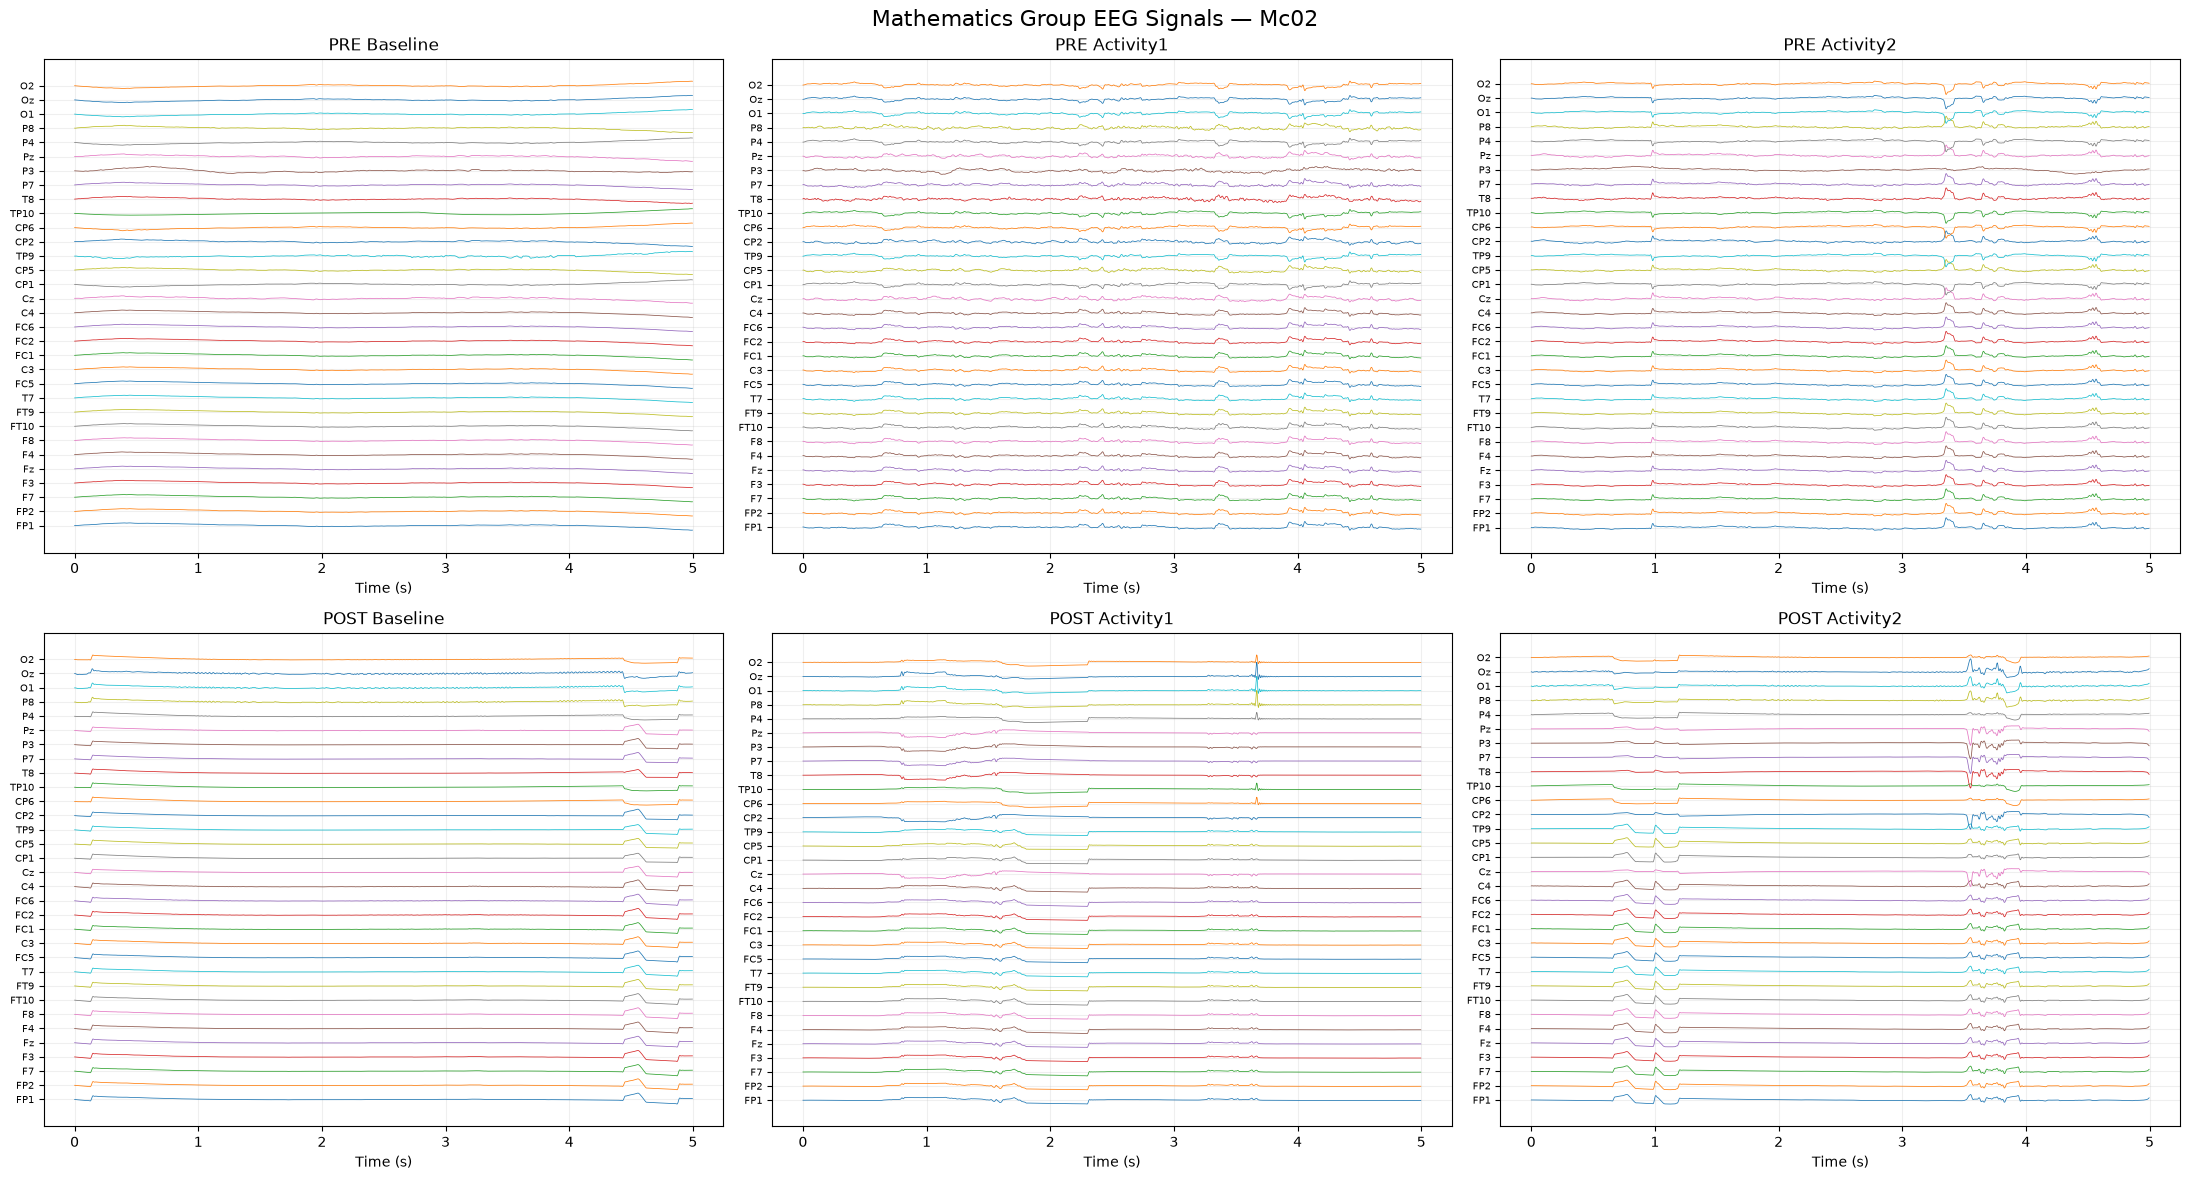

In [67]:
import numpy as np
import matplotlib.pyplot as plt

plot_order = [
    "PRE_Baseline", "PRE_Activity1", "PRE_Activity2",
    "POST_Baseline", "POST_Activity1", "POST_Activity2"
]

start_time, end_time = PLOT_WINDOW_SECONDS
fig, axes = plt.subplots(2, 3, figsize=(22, 12), sharex=False)
axes = axes.flatten()
spacing = 10

for ax, recording_name in zip(axes, plot_order):
    raw = raw_clean_files[recording_name]
    sfreq = raw.info["sfreq"]
    start_sample = max(0, int(start_time * sfreq))
    stop_sample = min(raw.n_times, int(end_time * sfreq))
    data = raw.get_data(start=start_sample, stop=stop_sample)
    times = raw.times[start_sample:stop_sample]

    for ch_idx, signal in enumerate(data):
        std = np.std(signal)
        normalized = (
            (signal - np.mean(signal)) / std
            if std > 0 else signal - np.mean(signal)
        )
        ax.plot(times, normalized + ch_idx * spacing, linewidth=0.55)

    ax.set_title(recording_name.replace("_", " "))
    ax.set_xlabel("Time (s)")
    ax.set_yticks(
        np.arange(0, len(raw.ch_names) * spacing, spacing),
        raw.ch_names,
        fontsize=7
    )
    ax.grid(alpha=0.2)

fig.suptitle(
    f"Mathematics Group EEG Signals — {SUBJECT_ID}",
    fontsize=16
)
plt.tight_layout()
plt.show()

## 6. Signal plots — PRE vs POST activity runs

Activity 1 is compared with its matching POST Activity 1 recording, and Activity 2 with its matching POST Activity 2 recording. The PRE and POST baseline recordings are not mixed into these activity comparisons.

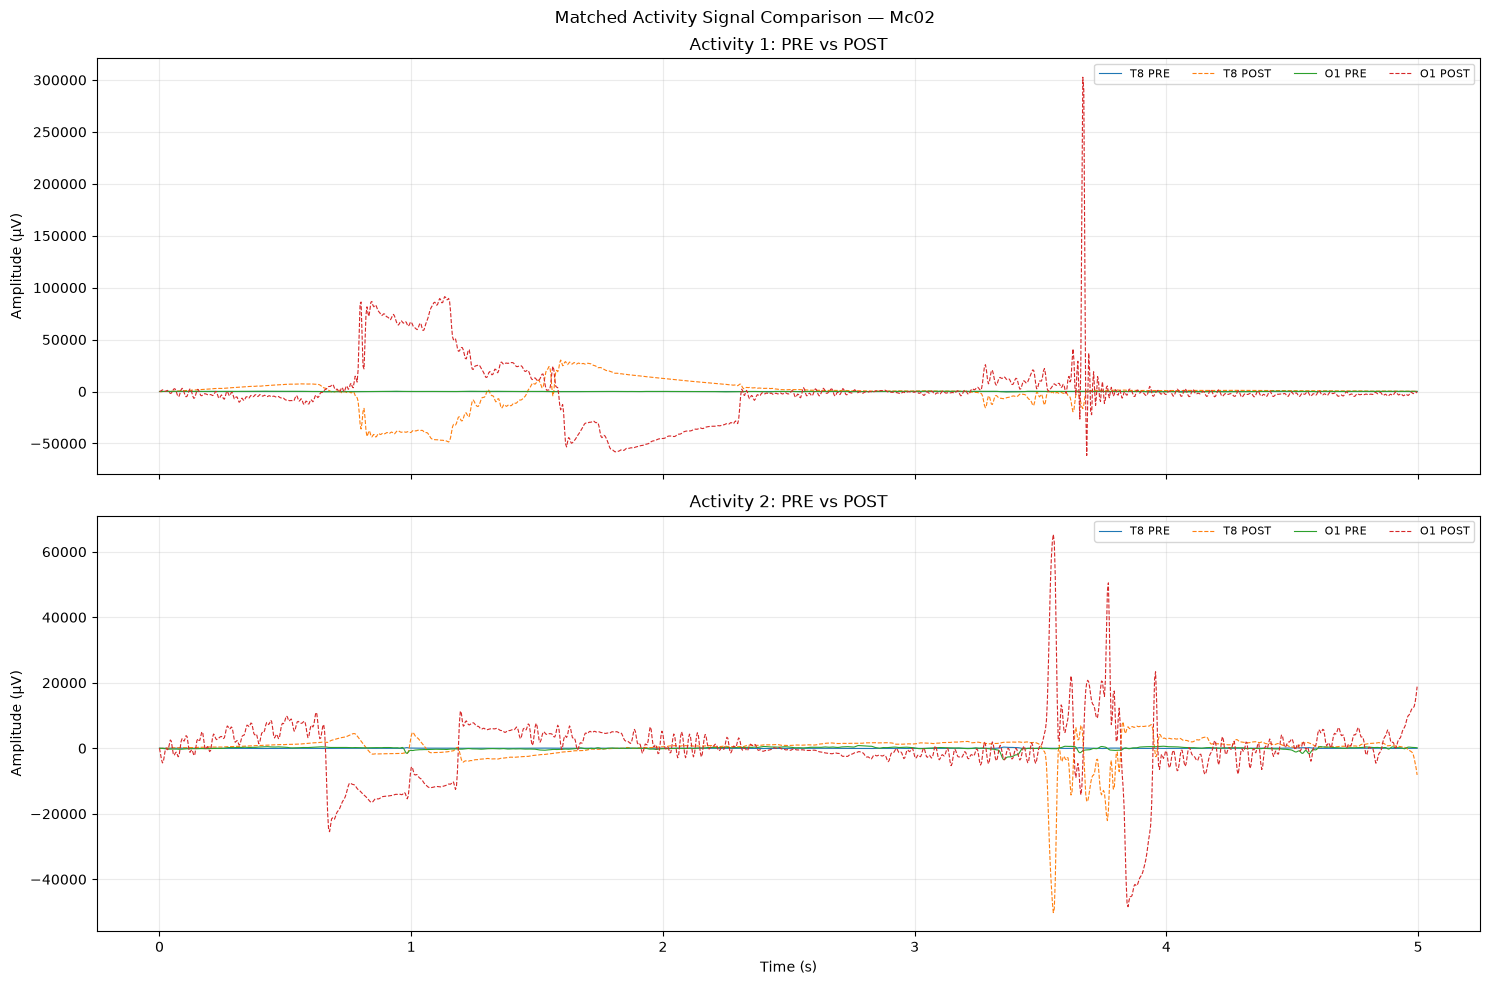

In [68]:
import numpy as np
import matplotlib.pyplot as plt

comparison_pairs = [
    ("Activity 1", "PRE_Activity1", "POST_Activity1"),
    ("Activity 2", "PRE_Activity2", "POST_Activity2")
]

channels_to_plot = [
    ch for ch in SELECTED_CHANNELS
    if ch in raw_clean_files["PRE_Activity1"].ch_names
]

if not channels_to_plot:
    raise ValueError(
        "None of SELECTED_CHANNELS are present in the recordings."
    )

start_time, end_time = PLOT_WINDOW_SECONDS
fig, axes = plt.subplots(
    len(comparison_pairs), 1,
    figsize=(15, 5 * len(comparison_pairs)),
    sharex=True
)
axes = np.atleast_1d(axes)

for ax, (label, pre_name, post_name) in zip(axes, comparison_pairs):
    for channel in channels_to_plot:
        for recording_name, linestyle in [
            (pre_name, "-"), (post_name, "--")
        ]:
            raw = raw_clean_files[recording_name]
            sfreq = raw.info["sfreq"]
            start = max(0, int(start_time * sfreq))
            stop = min(raw.n_times, int(end_time * sfreq))
            signal = raw.get_data(
                picks=[channel], start=start, stop=stop
            )[0] * 1e6
            times = raw.times[start:stop]
            ax.plot(
                times, signal, linestyle=linestyle,
                linewidth=0.8,
                label=f"{channel} {recording_name.split('_')[0]}"
            )

    ax.set_title(f"{label}: PRE vs POST")
    ax.set_ylabel("Amplitude (µV)")
    ax.grid(alpha=0.25)
    ax.legend(ncol=4, fontsize=8)

axes[-1].set_xlabel("Time (s)")
fig.suptitle(f"Matched Activity Signal Comparison — {SUBJECT_ID}")
plt.tight_layout()
plt.show()

## 7. Selected-channel signal inspection

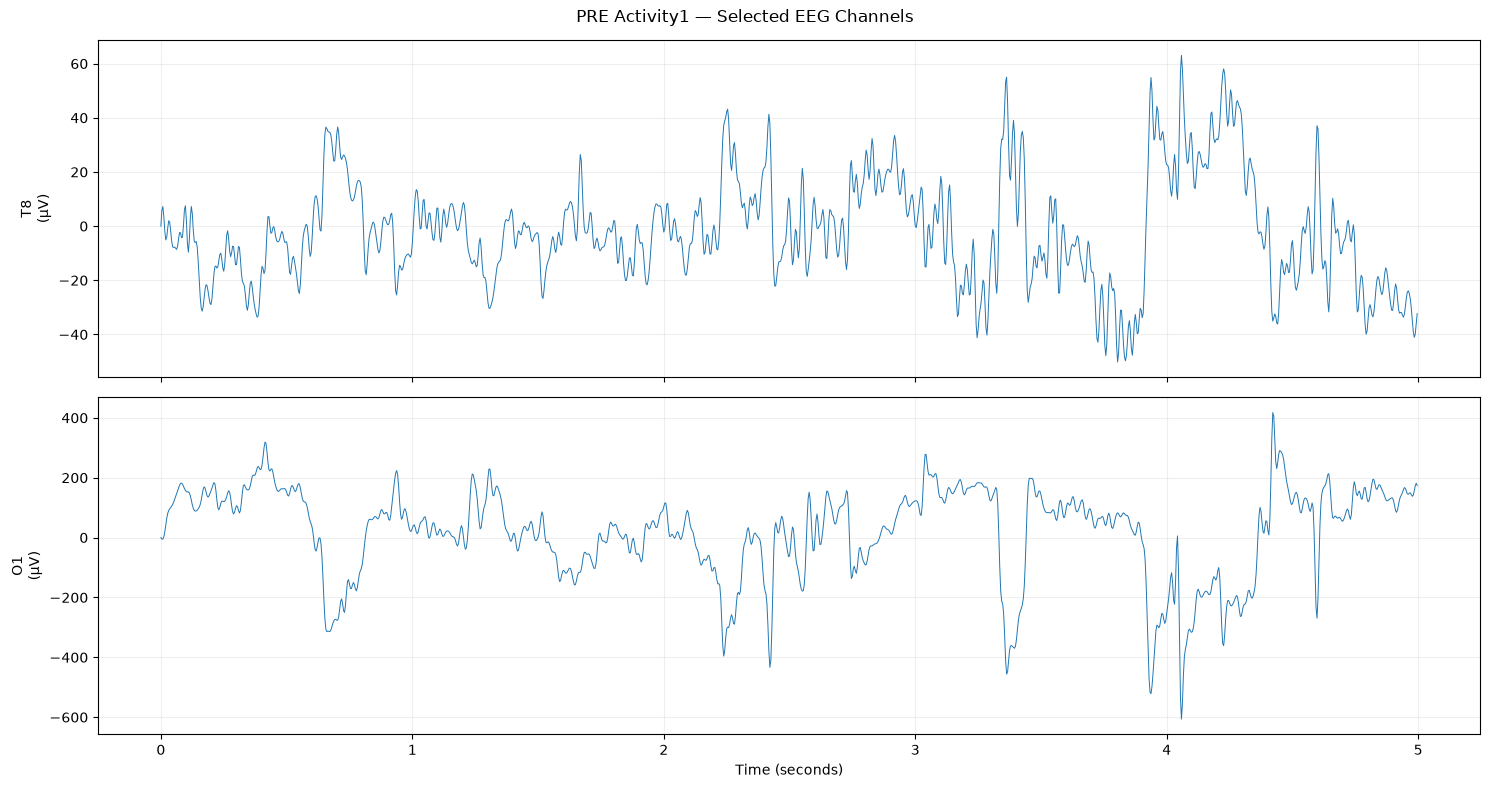

In [69]:
import matplotlib.pyplot as plt
import numpy as np

recording_name = SELECTED_SIGNAL_RECORDING
if recording_name not in raw_clean_files:
    raise ValueError(
        f"Unknown SELECTED_SIGNAL_RECORDING: {recording_name}"
    )

raw = raw_clean_files[recording_name]
missing_channels = [
    ch for ch in SELECTED_CHANNELS if ch not in raw.ch_names
]
if missing_channels:
    raise ValueError(
        f"Channels not found in {recording_name}: {missing_channels}"
    )

start_time, end_time = PLOT_WINDOW_SECONDS
sfreq = raw.info["sfreq"]
start = max(0, int(start_time * sfreq))
stop = min(raw.n_times, int(end_time * sfreq))
data = raw.get_data(start=start, stop=stop) * 1e6
times = raw.times[start:stop]

fig, axes = plt.subplots(
    len(SELECTED_CHANNELS), 1,
    figsize=(15, 4 * len(SELECTED_CHANNELS)),
    sharex=True
)
axes = np.atleast_1d(axes)

for ax, channel in zip(axes, SELECTED_CHANNELS):
    idx = raw.ch_names.index(channel)
    ax.plot(times, data[idx], linewidth=0.7)
    ax.set_ylabel(f"{channel}\n(µV)")
    ax.grid(alpha=0.2)

axes[-1].set_xlabel("Time (seconds)")
fig.suptitle(
    f"{recording_name.replace('_', ' ')} — Selected EEG Channels"
)
plt.tight_layout()
plt.show()

## 8. PSD — baseline vs both activity runs

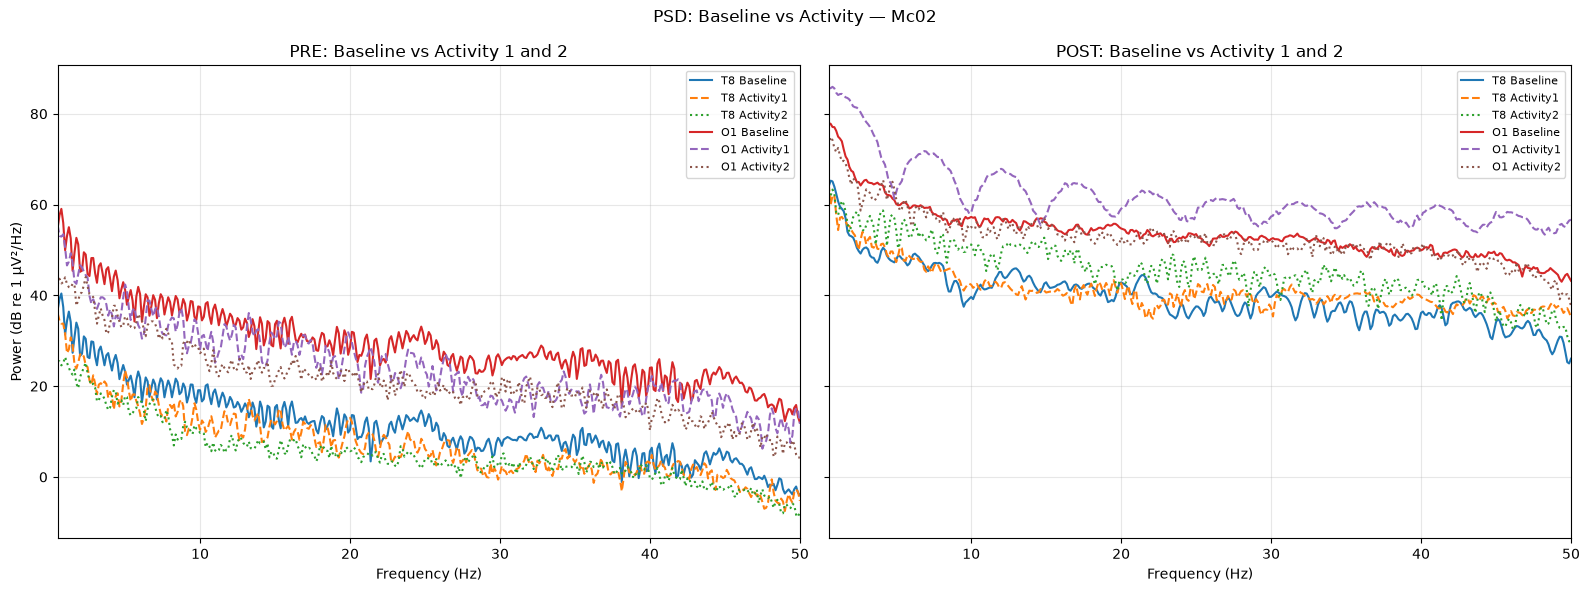

In [70]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import welch

def get_psd(raw, channel):
    eeg_uv = raw.get_data(picks=[channel])[0] * 1e6
    sfreq = raw.info["sfreq"]
    nperseg = min(2048, len(eeg_uv))
    freqs, psd = welch(
        eeg_uv, fs=sfreq,
        nperseg=nperseg,
        noverlap=nperseg // 2,
        scaling="density"
    )
    mask = (freqs >= 0.5) & (freqs <= 50)
    return freqs[mask], 10 * np.log10(psd[mask] + 1e-20)

fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)

for ax, session, baseline_name, activity1_name, activity2_name in [
    (axes[0], "PRE", "PRE_Baseline", "PRE_Activity1", "PRE_Activity2"),
    (axes[1], "POST", "POST_Baseline", "POST_Activity1", "POST_Activity2")
]:
    for channel in SELECTED_CHANNELS:
        if channel not in raw_clean_files[baseline_name].ch_names:
            continue
        f, p = get_psd(raw_clean_files[baseline_name], channel)
        ax.plot(f, p, label=f"{channel} Baseline", linewidth=1.5)

        for activity_name, style in [
            (activity1_name, "--"), (activity2_name, ":")
        ]:
            f, p = get_psd(raw_clean_files[activity_name], channel)
            ax.plot(
                f, p, linestyle=style,
                label=f"{channel} {activity_name.split('_')[-1]}"
            )

    ax.set_title(f"{session}: Baseline vs Activity 1 and 2")
    ax.set_xlabel("Frequency (Hz)")
    ax.set_xlim(0.5, 50)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

axes[0].set_ylabel("Power (dB re 1 µV²/Hz)")
fig.suptitle(f"PSD: Baseline vs Activity — {SUBJECT_ID}")
plt.tight_layout()
plt.show()

## 9. O1 PSD — baseline and both activity runs

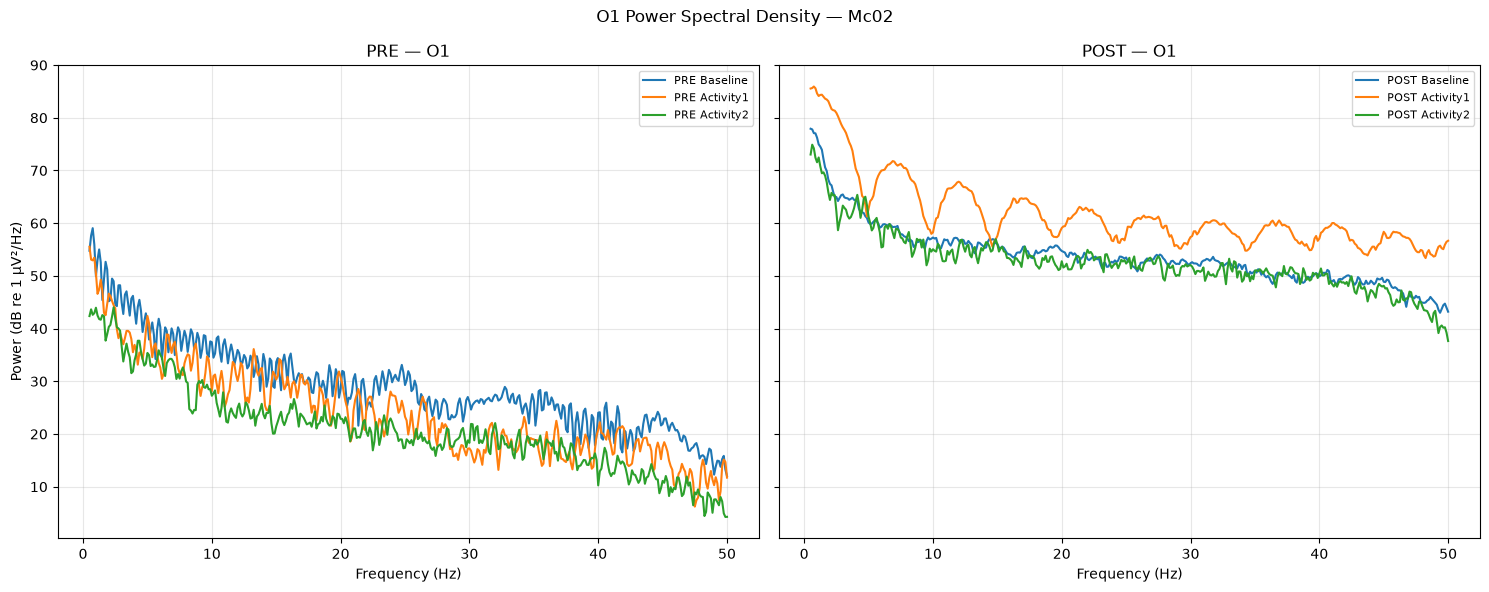

In [71]:
import matplotlib.pyplot as plt
from scipy.signal import welch
import numpy as np

channel = "O1"
if channel not in raw_clean_files["PRE_Baseline"].ch_names:
    raise ValueError(f"Channel {channel} is not present.")

def channel_psd_db(raw, channel):
    signal_uv = raw.get_data(picks=[channel])[0] * 1e6
    sfreq = raw.info["sfreq"]
    nperseg = min(2048, len(signal_uv))
    freqs, psd = welch(
        signal_uv, fs=sfreq, nperseg=nperseg,
        noverlap=nperseg // 2
    )
    mask = (freqs >= 0.5) & (freqs <= 50)
    return freqs[mask], 10 * np.log10(psd[mask] + 1e-20)

fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharey=True)

for ax, session, names in [
    (axes[0], "PRE", ["PRE_Baseline", "PRE_Activity1", "PRE_Activity2"]),
    (axes[1], "POST", ["POST_Baseline", "POST_Activity1", "POST_Activity2"])
]:
    for name in names:
        freqs, psd_db = channel_psd_db(raw_clean_files[name], channel)
        ax.plot(freqs, psd_db, label=name.replace("_", " "))
    ax.set_title(f"{session} — O1")
    ax.set_xlabel("Frequency (Hz)")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

axes[0].set_ylabel("Power (dB re 1 µV²/Hz)")
fig.suptitle(f"O1 Power Spectral Density — {SUBJECT_ID}")
plt.tight_layout()
plt.show()

## 10. Event-window PSD — optional, requires verified event times

No fixed timestamps are carried over from the Mathematics group. Set the relevant entries in `EVENT_TIMES` only after checking the Mathematics event TSV and confirming what the event codes mean. If the times remain `None`, this cell safely skips event-window PSD.

In [72]:
import matplotlib.pyplot as plt
from scipy.signal import welch
import numpy as np

def segment_psd_db(raw, channel, center_time, before=2.0, after=3.0):
    start_time = center_time - before
    end_time = center_time + after
    if start_time < 0 or end_time > raw.times[-1]:
        raise ValueError(
            f"Event window {start_time:.3f}–{end_time:.3f}s "
            "falls outside the recording."
        )

    sfreq = raw.info["sfreq"]
    start = int(start_time * sfreq)
    stop = int(end_time * sfreq)
    signal_uv = raw.get_data(
        picks=[channel], start=start, stop=stop
    )[0] * 1e6

    if len(signal_uv) < 32:
        raise ValueError("Event segment is too short for PSD.")

    nperseg = min(512, len(signal_uv))
    freqs, psd = welch(
        signal_uv, fs=sfreq, nperseg=nperseg,
        noverlap=nperseg // 2
    )
    mask = (freqs >= 0.5) & (freqs <= 50)
    return freqs[mask], 10 * np.log10(psd[mask] + 1e-20)

configured_event_recordings = [
    name for name, timestamp in EVENT_TIMES.items()
    if timestamp is not None
]

if not configured_event_recordings:
    print(
        "Event-window PSD skipped: no verified Math-group event times "
        "have been entered in EVENT_TIMES."
    )
else:
    fig, axes = plt.subplots(
        len(configured_event_recordings), 1,
        figsize=(13, 5 * len(configured_event_recordings)),
        sharex=True
    )
    axes = np.atleast_1d(axes)

    for ax, recording_name in zip(axes, configured_event_recordings):
        raw = raw_clean_files[recording_name]
        event_time = float(EVENT_TIMES[recording_name])

        for channel in SELECTED_CHANNELS:
            if channel not in raw.ch_names:
                continue
            freqs, psd_db = segment_psd_db(
                raw, channel, event_time,
                EVENT_WINDOW_BEFORE, EVENT_WINDOW_AFTER
            )
            ax.plot(freqs, psd_db, label=channel)

        ax.set_title(
            f"{recording_name.replace('_', ' ')} — event at {event_time:.3f}s"
        )
        ax.set_ylabel("Power (dB re 1 µV²/Hz)")
        ax.grid(alpha=0.3)
        ax.legend()

    axes[-1].set_xlabel("Frequency (Hz)")
    plt.tight_layout()
    plt.show()

Event-window PSD skipped: no verified Math-group event times have been entered in EVENT_TIMES.


## 11. Overall PSD — PRE vs POST matched activity runs
Activity 1 is compared only with Activity 1; Activity 2 is compared only with Activity 2.

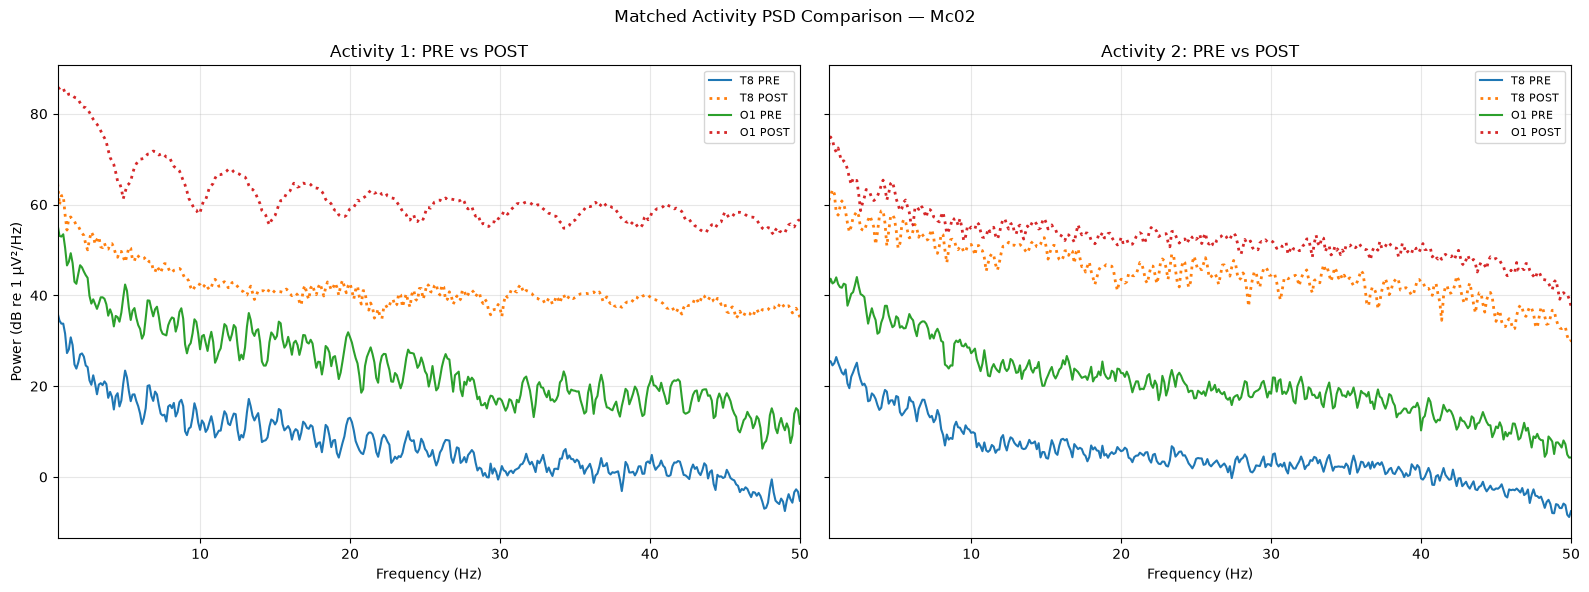

In [73]:
import matplotlib.pyplot as plt
from scipy.signal import welch
import numpy as np

def calculate_psd_db(raw, channel):
    signal_uv = raw.get_data(picks=[channel])[0] * 1e6
    sfreq = raw.info["sfreq"]
    nperseg = min(2048, len(signal_uv))
    freqs, power = welch(
        signal_uv, fs=sfreq, nperseg=nperseg,
        noverlap=nperseg // 2
    )
    mask = (freqs >= 0.5) & (freqs <= 50)
    return freqs[mask], 10 * np.log10(power[mask] + 1e-20)

activity_pairs = [
    ("Activity 1", "PRE_Activity1", "POST_Activity1"),
    ("Activity 2", "PRE_Activity2", "POST_Activity2")
]

fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)

for ax, (label, pre_name, post_name) in zip(axes, activity_pairs):
    for channel in SELECTED_CHANNELS:
        if channel not in raw_clean_files[pre_name].ch_names:
            continue
        f_pre, p_pre = calculate_psd_db(
            raw_clean_files[pre_name], channel
        )
        f_post, p_post = calculate_psd_db(
            raw_clean_files[post_name], channel
        )
        ax.plot(f_pre, p_pre, label=f"{channel} PRE")
        ax.plot(
            f_post, p_post, linestyle=":",
            linewidth=2, label=f"{channel} POST"
        )

    ax.set_title(f"{label}: PRE vs POST")
    ax.set_xlabel("Frequency (Hz)")
    ax.set_xlim(0.5, 50)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

axes[0].set_ylabel("Power (dB re 1 µV²/Hz)")
fig.suptitle(f"Matched Activity PSD Comparison — {SUBJECT_ID}")
plt.tight_layout()
plt.show()

## 12. Event-related PSD — PRE vs POST matched activity runs

This comparison runs only when both PRE and POST event times for the same activity run have been verified and entered in `EVENT_TIMES`.

In [74]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.signal import welch

event_activity_pairs = [
    ("Activity 1", "PRE_Activity1", "POST_Activity1"),
    ("Activity 2", "PRE_Activity2", "POST_Activity2")
]

available_pairs = [
    pair for pair in event_activity_pairs
    if EVENT_TIMES.get(pair[1]) is not None
    and EVENT_TIMES.get(pair[2]) is not None
]

if not available_pairs:
    print(
        "PRE–POST event-related PSD skipped: enter verified event times "
        "for both sessions of Activity 1 and/or Activity 2 in EVENT_TIMES."
    )
else:
    fig, axes = plt.subplots(
        len(available_pairs), 1,
        figsize=(13, 5 * len(available_pairs)),
        sharex=True
    )
    axes = np.atleast_1d(axes)

    for ax, (label, pre_name, post_name) in zip(axes, available_pairs):
        for channel in SELECTED_CHANNELS:
            if channel not in raw_clean_files[pre_name].ch_names:
                continue

            f_pre, p_pre = segment_psd_db(
                raw_clean_files[pre_name], channel,
                float(EVENT_TIMES[pre_name]),
                EVENT_WINDOW_BEFORE, EVENT_WINDOW_AFTER
            )
            f_post, p_post = segment_psd_db(
                raw_clean_files[post_name], channel,
                float(EVENT_TIMES[post_name]),
                EVENT_WINDOW_BEFORE, EVENT_WINDOW_AFTER
            )

            ax.plot(f_pre, p_pre, label=f"{channel} PRE")
            ax.plot(
                f_post, p_post, linestyle=":",
                linewidth=2, label=f"{channel} POST"
            )

        ax.set_title(f"{label}: Event-related PRE vs POST")
        ax.set_ylabel("Power (dB re 1 µV²/Hz)")
        ax.grid(alpha=0.3)
        ax.legend()

    axes[-1].set_xlabel("Frequency (Hz)")
    plt.tight_layout()
    plt.show()

PRE–POST event-related PSD skipped: enter verified event times for both sessions of Activity 1 and/or Activity 2 in EVENT_TIMES.


## 13. Relative delta-band power across all six recordings

This preserves the original relative delta-power visualization, expanded to show all six Mathematics recordings.

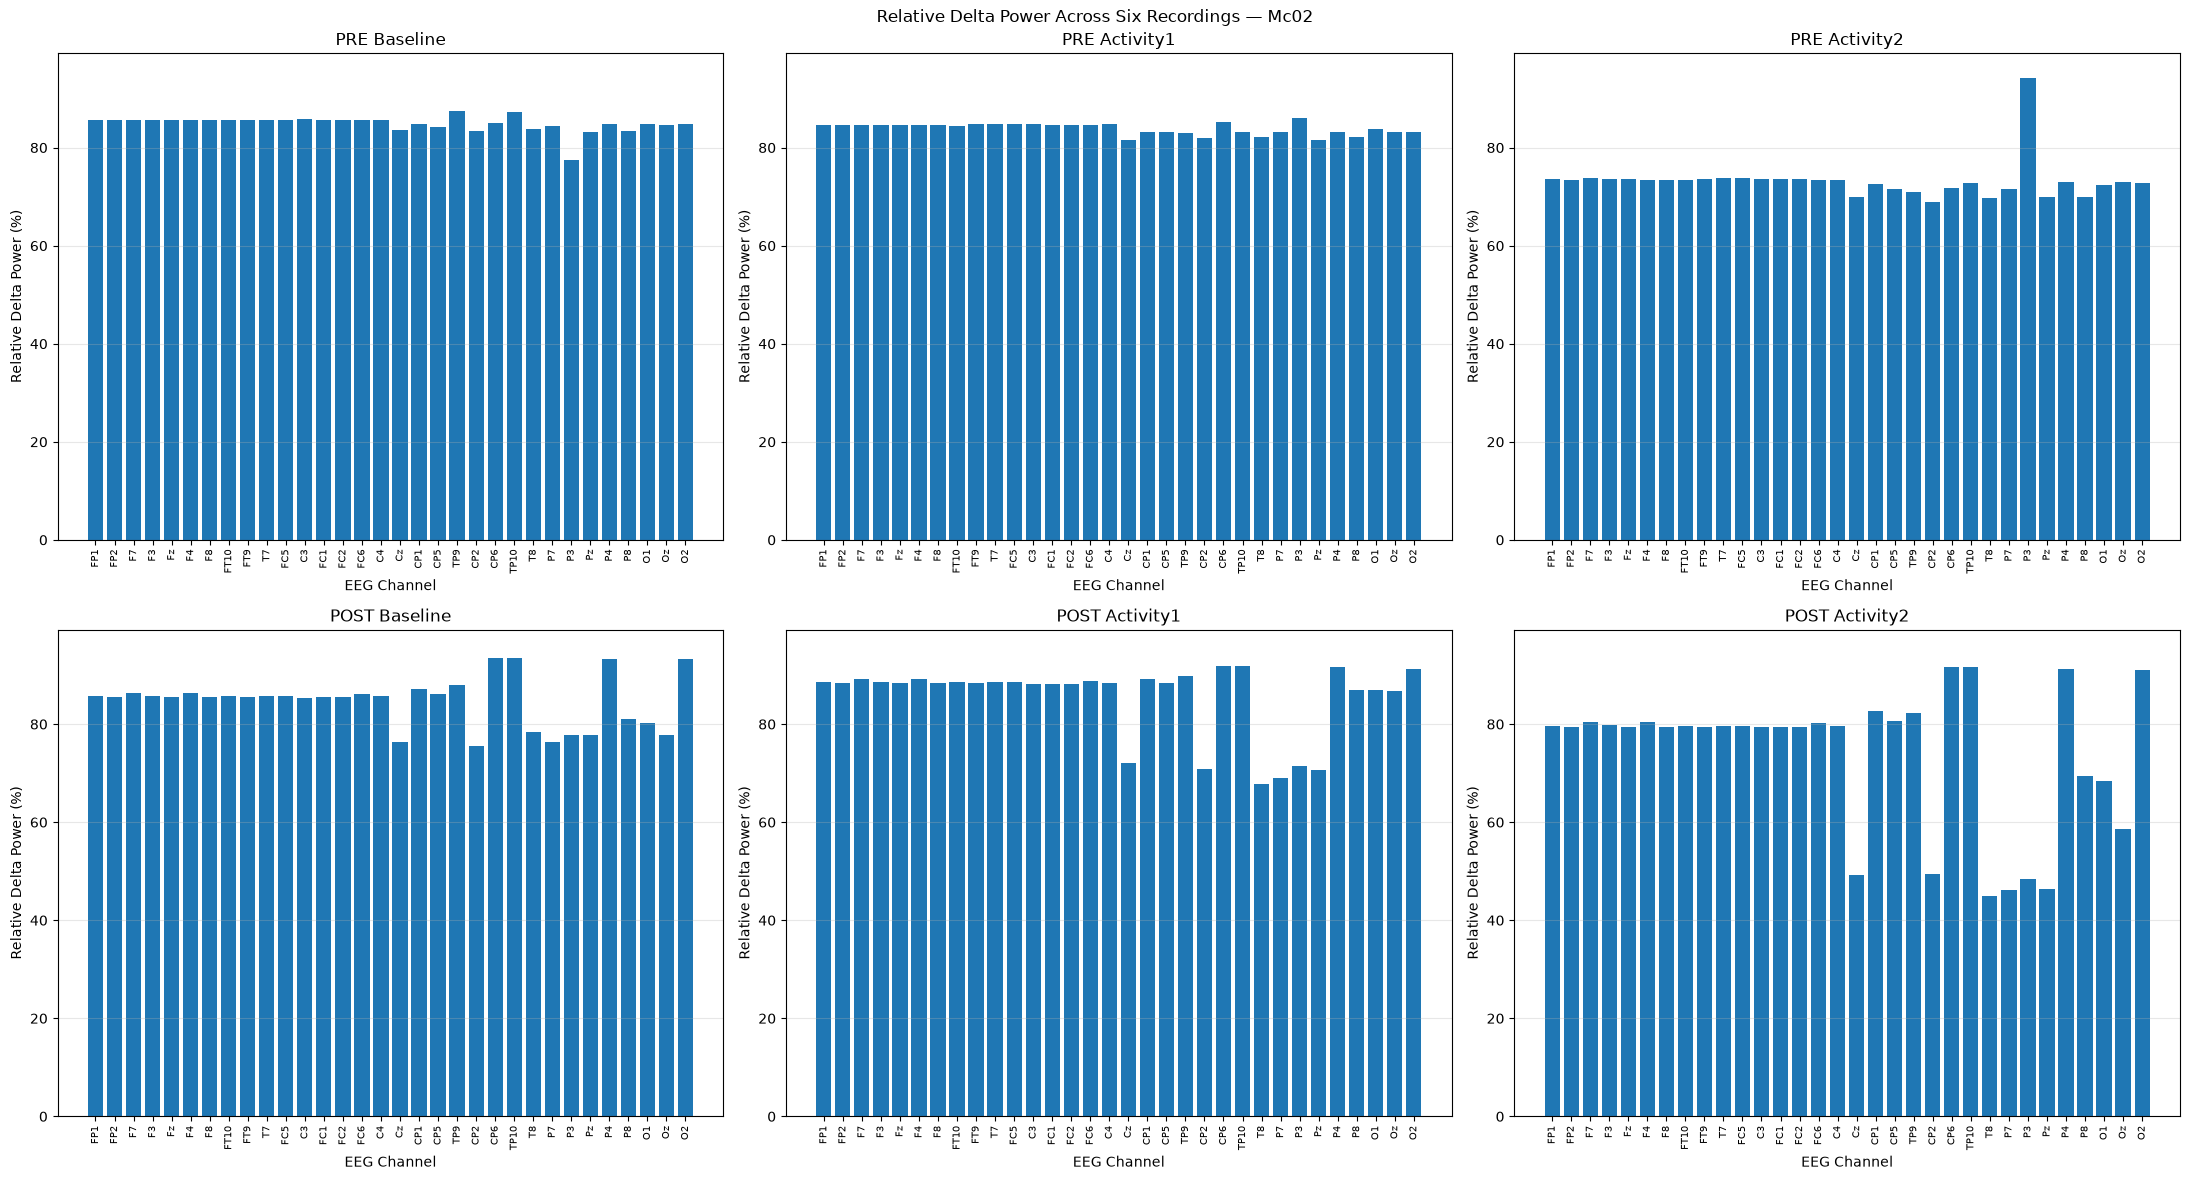

In [75]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import welch

recording_order = [
    "PRE_Baseline", "PRE_Activity1", "PRE_Activity2",
    "POST_Baseline", "POST_Activity1", "POST_Activity2"
]
delta_range = (0.5, 4.0)
total_range = (0.5, 50.0)
relative_delta_by_recording = {}

integrate = getattr(np, "trapezoid", None)
if integrate is None:
    integrate = np.trapz

for name in recording_order:
    raw = raw_clean_files[name]
    values = []

    for channel in raw.ch_names:
        signal_uv = raw.get_data(picks=[channel])[0] * 1e6
        nperseg = min(2048, len(signal_uv))
        freqs, psd = welch(
            signal_uv, fs=raw.info["sfreq"],
            nperseg=nperseg,
            noverlap=nperseg // 2
        )

        delta_mask = (
            (freqs >= delta_range[0]) & (freqs <= delta_range[1])
        )
        total_mask = (
            (freqs >= total_range[0]) & (freqs <= total_range[1])
        )

        delta_power = integrate(psd[delta_mask], freqs[delta_mask])
        total_power = integrate(psd[total_mask], freqs[total_mask])

        values.append(
            delta_power / total_power * 100
            if total_power > 0 else np.nan
        )

    relative_delta_by_recording[name] = values

max_power = max(
    np.nanmax(values)
    for values in relative_delta_by_recording.values()
)

fig, axes = plt.subplots(2, 3, figsize=(22, 12))
axes = axes.flatten()

for ax, name in zip(axes, recording_order):
    raw = raw_clean_files[name]
    ax.bar(raw.ch_names, relative_delta_by_recording[name])
    ax.set_xlabel("EEG Channel")
    ax.set_ylabel("Relative Delta Power (%)")
    ax.set_title(name.replace("_", " "))
    ax.tick_params(axis="x", rotation=90, labelsize=7)
    ax.grid(axis="y", alpha=0.3)
    ax.set_ylim(0, max_power + 5)

fig.suptitle(f"Relative Delta Power Across Six Recordings — {SUBJECT_ID}")
plt.tight_layout()
plt.show()

## 14. Gamma-band power — PRE and POST baseline

In [76]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import welch

gamma_results = {}

for recording_name in ["PRE_Baseline", "POST_Baseline"]:
    raw = raw_clean_files[recording_name]
    gamma_power = []

    for channel in raw.ch_names:
        signal_uv = raw.get_data(picks=[channel])[0] * 1e6
        nperseg = min(2048, len(signal_uv))
        freqs, psd = welch(
            signal_uv,
            fs=raw.info["sfreq"],
            nperseg=nperseg,
            noverlap=nperseg // 2
        )
        gamma_mask = (freqs >= 30) & (freqs <= 50)
        integrate = getattr(np, "trapezoid", None)
        if integrate is None:
            integrate = np.trapz
        gamma_power.append(
            float(integrate(psd[gamma_mask], freqs[gamma_mask]))
        )

    gamma_results[recording_name] = gamma_power

fig, axes = plt.subplots(1, 2, figsize=(20, 6), sharey=True)

for ax, recording_name in zip(
    axes, ["PRE_Baseline", "POST_Baseline"]
):
    raw = raw_clean_files[recording_name]
    ax.bar(raw.ch_names, gamma_results[recording_name])
    ax.set_xlabel("EEG Channel")
    ax.set_ylabel(r"Gamma Band Power ($\mu V^2$)")
    ax.set_title(recording_name.replace("_", " "))
    ax.tick_params(axis="x", rotation=90, labelsize=7)
    ax.grid(axis="y", alpha=0.3)

fig.suptitle(f"Baseline Gamma-Band Power — {SUBJECT_ID}")
plt.tight_layout()
plt.show()

ValueError: cannot convert float NaN to integer

<Figure size 2000x600 with 2 Axes>

## 15. Extract absolute and relative power for all five frequency bands

Each row represents one subject × recording × channel × frequency band. A fully valid Mathematics subject has six recordings × 32 channels × five bands = **960 rows**.

In [77]:
FREQUENCY_BANDS = {
    "delta": (0.5, 4.0),
    "theta": (4.0, 8.0),
    "alpha": (8.0, 13.0),
    "beta": (13.0, 30.0),
    "gamma": (30.0, 50.0),
}
TOTAL_POWER_RANGE = (0.5, 50.0)

def integrate_psd(freqs, psd, low, high):
    mask = (freqs >= low) & (freqs <= high)
    if mask.sum() < 2:
        return np.nan
    integrate = getattr(np, "trapezoid", None)
    if integrate is None:
        integrate = np.trapz
    return float(integrate(psd[mask], freqs[mask]))

def calculate_channel_band_powers(raw, channel):
    signal_uv = raw.get_data(picks=[channel])[0] * 1e6
    sfreq = float(raw.info["sfreq"])
    nperseg = min(2048, len(signal_uv))

    freqs, psd = welch(
        signal_uv,
        fs=sfreq,
        nperseg=nperseg,
        noverlap=nperseg // 2,
        scaling="density"
    )

    total_power = integrate_psd(
        freqs, psd, *TOTAL_POWER_RANGE
    )

    results = {}
    for band, (low, high) in FREQUENCY_BANDS.items():
        band_power = integrate_psd(freqs, psd, low, high)
        relative_power = (
            band_power / total_power * 100
            if np.isfinite(total_power) and total_power > 0
            else np.nan
        )

        results[band] = {
            "frequency_min": low,
            "frequency_max": high,
            "absolute_power": band_power,
            "relative_power": relative_power,
        }

    return results

result_rows = []

for recording_name, raw in raw_clean_files.items():
    session, run = RECORDINGS[recording_name]
    condition = _math_condition(recording_name)

    for channel in raw.ch_names:
        channel_results = calculate_channel_band_powers(raw, channel)

        for band, values in channel_results.items():
            if (
                not np.isfinite(values["absolute_power"])
                or not np.isfinite(values["relative_power"])
            ):
                raise ValueError(
                    f"Non-finite result: {recording_name}, {channel}, {band}"
                )

            result_rows.append({
                "subject_id": SUBJECT_ID,
                "session": session,
                "run": run,
                "condition": condition,
                "sampling_frequency": float(raw.info["sfreq"]),
                "duration": float(raw.times[-1]),
                "channel_count": len(raw.ch_names),
                "sample_count": raw.n_times,
                "channel": channel,
                "band": band,
                "frequency_min": values["frequency_min"],
                "frequency_max": values["frequency_max"],
                "absolute_power": values["absolute_power"],
                "relative_power": values["relative_power"],
                "event_id": "",
                "event_onset": np.nan,
                "event_duration": np.nan,
                "event_code": "",
            })

subject_results_df = pd.DataFrame(result_rows)
expected_subject_rows = (
    len(RECORDINGS)
    * len(raw_clean1.ch_names)
    * len(FREQUENCY_BANDS)
)

print("Rows generated:", len(subject_results_df))
print("Expected rows:", expected_subject_rows)
display(subject_results_df.head(10))

Rows generated: 960
Expected rows: 960


,subject_id,session,run,condition,sampling_frequency,duration,channel_count,sample_count,channel,band,frequency_min,frequency_max,absolute_power,relative_power,event_id,event_onset,event_duration,event_code
0,Mc02,ses-1,1,Baseline,256.0,179.996094,32,46080,FP1,delta,0.5,4.0,86283.716421,85.680852,,NaN,NaN,
1,Mc02,ses-1,1,Baseline,256.0,179.996094,32,46080,FP1,theta,4.0,8.0,7103.171257,7.053541,,NaN,NaN,
2,Mc02,ses-1,1,Baseline,256.0,179.996094,32,46080,FP1,alpha,8.0,13.0,3651.273938,3.625762,,NaN,NaN,
3,Mc02,ses-1,1,Baseline,256.0,179.996094,32,46080,FP1,beta,13.0,30.0,2882.075668,2.861939,,NaN,NaN,
4,Mc02,ses-1,1,Baseline,256.0,179.996094,32,46080,FP1,gamma,30.0,50.0,783.378528,0.777905,,NaN,NaN,
5,Mc02,ses-1,1,Baseline,256.0,179.996094,32,46080,FP2,delta,0.5,4.0,85928.005718,85.668824,,NaN,NaN,
6,Mc02,ses-1,1,Baseline,256.0,179.996094,32,46080,FP2,theta,4.0,8.0,7060.164575,7.038869,,NaN,NaN,
7,Mc02,ses-1,1,Baseline,256.0,179.996094,32,46080,FP2,alpha,8.0,13.0,3650.482493,3.639472,,NaN,NaN,
8,Mc02,ses-1,1,Baseline,256.0,179.996094,32,46080,FP2,beta,13.0,30.0,2879.733898,2.871048,,NaN,NaN,
9,Mc02,ses-1,1,Baseline,256.0,179.996094,32,46080,FP2,gamma,30.0,50.0,784.152560,0.781787,,NaN,NaN,


## 16. Update the Mathematics master CSV

The CSV is cumulative across subjects. A successful reprocessing run replaces only the selected subject's previous rows; all other subjects are preserved.

In [78]:
CSV_COLUMNS = [
    "subject_id", "session", "run", "condition",
    "sampling_frequency", "duration", "channel_count", "sample_count",
    "channel", "band", "frequency_min", "frequency_max",
    "absolute_power", "relative_power",
    "event_id", "event_onset", "event_duration", "event_code"
]

UNIQUE_KEYS = [
    "subject_id", "session", "run", "channel", "band", "event_id"
]

def save_subject_results(new_data):
    if new_data is None or new_data.empty:
        raise ValueError(
            "No subject results were generated. Existing CSV was not changed."
        )

    expected_rows = (
        len(RECORDINGS)
        * len(raw_clean1.ch_names)
        * len(FREQUENCY_BANDS)
    )
    if len(new_data) != expected_rows:
        raise ValueError(
            f"Refusing to save incomplete subject results: "
            f"expected {expected_rows}, found {len(new_data)}"
        )

    new_data = new_data.copy()
    new_data["subject_id"] = SUBJECT_ID

    for column in CSV_COLUMNS:
        if column not in new_data.columns:
            new_data[column] = np.nan
    new_data = new_data[CSV_COLUMNS]

    if CSV_FILE.exists():
        existing = pd.read_csv(CSV_FILE)
        for column in CSV_COLUMNS:
            if column not in existing.columns:
                existing[column] = np.nan
        existing = existing[CSV_COLUMNS]
        existing["subject_id"] = (
            existing["subject_id"].astype(str)
            .str.replace("sub-", "", regex=False)
        )
        existing = existing[existing["subject_id"] != SUBJECT_ID]
    else:
        existing = pd.DataFrame(columns=CSV_COLUMNS)

    combined = pd.concat([existing, new_data], ignore_index=True)
    combined["event_id"] = combined["event_id"].fillna("").astype(str)
    combined = combined.drop_duplicates(
        subset=UNIQUE_KEYS, keep="last"
    )
    combined = combined.sort_values(
        ["subject_id", "session", "run", "channel", "band"],
        na_position="last"
    ).reset_index(drop=True)

    temp_file = CSV_FILE.with_name(CSV_FILE.name + ".tmp")
    combined.to_csv(temp_file, index=False)
    temp_file.replace(CSV_FILE)

    print("Mathematics master CSV updated:", CSV_FILE)
    print("New rows for", SUBJECT_ID, ":", len(new_data))
    print("Total rows in master CSV:", len(combined))
    print(
        "Subjects in master CSV:",
        sorted(combined["subject_id"].dropna().unique())
    )

save_subject_results(subject_results_df)

Mathematics master CSV updated: /Users/ananyosen/Documents/Term Project/Results/eeg_analysis_results_math_control.csv
New rows for Mc02 : 960
Total rows in master CSV: 14400
Subjects in master CSV: ['Mc02', 'Mc03', 'Mc04', 'Mc05', 'Mc06', 'Mc07', 'Mc09', 'Mc10', 'Mc11', 'Mc12', 'Mc13', 'Mc16', 'Mc18', 'Mc19', 'Mc20']


## 17. Final validation and Mathematics subject summary

In [79]:
print("GROUP: Mathematics")
print("SUBJECT:", BIDS_SUBJECT)
print("Recordings loaded:", len(raw_files))
print("Cleaned recordings:", len(raw_clean_files))
print("Band-power rows:", len(subject_results_df))
print("Channels per recording:", {
    name: len(raw.ch_names)
    for name, raw in raw_clean_files.items()
})

print("\nBand-power summary:")
display(
    subject_results_df.groupby(
        ["session", "condition", "band"]
    )[["absolute_power", "relative_power"]]
    .mean()
    .round(4)
)

print("\nMathematics master CSV exists:", CSV_FILE.exists())
print("CSV size (bytes):", CSV_FILE.stat().st_size if CSV_FILE.exists() else 0)

if CSV_FILE.exists():
    master = pd.read_csv(CSV_FILE)
    print("Subjects in Mathematics CSV:",
          sorted(master["subject_id"].dropna().unique()))
    print("Total master rows:", len(master))

if COHORT_AUDIT_FILE.exists():
    print("\nCohort processing audit:")
    display(pd.read_csv(COHORT_AUDIT_FILE))

GROUP: Mathematics
SUBJECT: sub-Mc02
Recordings loaded: 6
Cleaned recordings: 6
Band-power rows: 960
Channels per recording: {'PRE_Baseline': 32, 'PRE_Activity1': 32, 'PRE_Activity2': 32, 'POST_Baseline': 32, 'POST_Activity1': 32, 'POST_Activity2': 32}

Band-power summary:


absolute_power  relative_power
session condition band                                 
ses-1   Activity1 alpha    4.988157e+03          3.4035
                  beta     6.172669e+03          4.2074
                  delta    1.155081e+05         83.8903
                  gamma    8.053638e+02          0.5827
                  theta    1.103878e+04          7.9161
        Activity2 alpha    1.457034e+03          3.9681
                  beta     1.644997e+03          4.3999
                  delta    2.551456e+04         73.1800
                  gamma    5.394469e+02          1.4472
                  theta    6.334390e+03         17.0048
        Baseline  alpha    1.091060e+05          3.8615
                  beta     9.140464e+04          3.0149
                  delta    3.084992e+06         84.9410
                  gamma    2.841447e+04          0.8392
                  theta    2.283194e+05          7.3434
ses-2   Activity1 alpha    3.573856e+06          2.7165
                  beta     3.818693e+06          2.6776
                  delta    1.459514e+08         85.3966
                  gamma    1.986972e+06          1.6599
                  theta    7.923001e+06          7.5494
        Activity2 alpha    8.598195e+05          5.1691
                  beta     1.085234e+06          5.9642
                  delta    3.555757e+07         73.9691
                  gamma    3.693559e+05          1.9128
                  theta    2.833461e+06         12.9848
        Baseline  alpha    8.284848e+05          2.7986
                  beta     1.031079e+06          3.2773
                  delta    4.645550e+07         84.6168
                  gamma    3.682609e+05          1.1583
                  theta    2.362162e+06          8.1490


Mathematics master CSV exists: True
CSV size (bytes): 1547677
Subjects in Mathematics CSV: ['Mc02', 'Mc03', 'Mc04', 'Mc05', 'Mc06', 'Mc07', 'Mc09', 'Mc10', 'Mc11', 'Mc12', 'Mc13', 'Mc16', 'Mc18', 'Mc19', 'Mc20']
Total master rows: 14400

Cohort processing audit:


,subject_id,status,recordings_loaded,band_power_rows,missing_or_inconsistent_reason,PRE_Activity1_events_file,PRE_Activity2_events_file,POST_Activity1_events_file,POST_Activity2_events_file
0,Mc01,SKIPPED,0,0,ValueError: POST_Baseline: missing SET (sub-Mc...,False,False,False,False
1,Mc02,EXTRACTED,6,960,NaN,True,True,True,True
2,Mc03,EXTRACTED,6,960,NaN,False,True,True,True
3,Mc04,EXTRACTED,6,960,NaN,True,True,True,True
4,Mc05,EXTRACTED,6,960,NaN,True,True,True,True
5,Mc06,EXTRACTED,6,960,NaN,True,True,True,True
6,Mc07,EXTRACTED,6,960,NaN,True,True,True,True
7,Mc08,SKIPPED,0,0,ValueError: POST_Baseline: missing SET (sub-Mc...,False,False,False,False
8,Mc09,EXTRACTED,6,960,NaN,True,True,True,True
9,Mc10,EXTRACTED,6,960,NaN,True,True,True,True


## 18. Final validation and subject summary

In [80]:
print("SUBJECT:", BIDS_SUBJECT)
print("Recordings loaded:", len(raw_files))
print("Cleaned recordings:", len(raw_clean_files))
print("Band-power rows:", len(subject_results_df))
print("Channels per recording:", {
    name: len(raw.ch_names) for name, raw in raw_clean_files.items()
})
print("\nBand-power summary:")
display(
    subject_results_df.groupby(
        ["session", "condition", "band"]
    )[["absolute_power", "relative_power"]]
    .mean()
    .round(4)
)

print("\nCSV exists:", CSV_FILE.exists())
print("CSV size (bytes):", CSV_FILE.stat().st_size if CSV_FILE.exists() else 0)

SUBJECT: sub-Mc02
Recordings loaded: 6
Cleaned recordings: 6
Band-power rows: 960
Channels per recording: {'PRE_Baseline': 32, 'PRE_Activity1': 32, 'PRE_Activity2': 32, 'POST_Baseline': 32, 'POST_Activity1': 32, 'POST_Activity2': 32}

Band-power summary:


absolute_power  relative_power
session condition band                                 
ses-1   Activity1 alpha    4.988157e+03          3.4035
                  beta     6.172669e+03          4.2074
                  delta    1.155081e+05         83.8903
                  gamma    8.053638e+02          0.5827
                  theta    1.103878e+04          7.9161
        Activity2 alpha    1.457034e+03          3.9681
                  beta     1.644997e+03          4.3999
                  delta    2.551456e+04         73.1800
                  gamma    5.394469e+02          1.4472
                  theta    6.334390e+03         17.0048
        Baseline  alpha    1.091060e+05          3.8615
                  beta     9.140464e+04          3.0149
                  delta    3.084992e+06         84.9410
                  gamma    2.841447e+04          0.8392
                  theta    2.283194e+05          7.3434
ses-2   Activity1 alpha    3.573856e+06          2.7165
                  beta     3.818693e+06          2.6776
                  delta    1.459514e+08         85.3966
                  gamma    1.986972e+06          1.6599
                  theta    7.923001e+06          7.5494
        Activity2 alpha    8.598195e+05          5.1691
                  beta     1.085234e+06          5.9642
                  delta    3.555757e+07         73.9691
                  gamma    3.693559e+05          1.9128
                  theta    2.833461e+06         12.9848
        Baseline  alpha    8.284848e+05          2.7986
                  beta     1.031079e+06          3.2773
                  delta    4.645550e+07         84.6168
                  gamma    3.682609e+05          1.1583
                  theta    2.362162e+06          8.1490


CSV exists: True
CSV size (bytes): 1547677
